In [31]:
# 10 — XGBoost Station Forecast: Poisson Objective
#
# Same features and hyperparameters as notebook 06, but with
#   objective='count:poisson'
# instead of reg:squarederror.
#
# Poisson NLL is theoretically better for count data:
#   - predictions are naturally non-negative (no clipping needed)
#   - loss is scale-aware (relative errors matter more for small counts)
#
# Final cell compares metrics side-by-side with the MSE model from notebook 06.


In [32]:
## 1. Setup
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from dotenv import load_dotenv
from divvy_demand.infra.s3_client import S3Client

load_dotenv('../../.env')
s3 = S3Client(env='prod')

def smape(y_true, y_pred):
    return np.mean(2 * np.abs(y_pred - y_true) / (np.abs(y_true) + np.abs(y_pred))) * 100

def mape(y_true, y_pred):
    mask = y_true != 0
    return np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100

def mase(y_true, y_pred, y_train):
    naive_mae = np.mean(np.abs(np.diff(y_train)))
    return mean_absolute_error(y_true, y_pred) / naive_mae

def metrics_dict(y_true, y_pred, y_tr):
    return {
        'R2':    r2_score(y_true, y_pred),
        'RMSE':  mean_squared_error(y_true, y_pred) ** 0.5,
        'MAE':   mean_absolute_error(y_true, y_pred),
        'sMAPE': smape(y_true.values, y_pred),
        'MASE':  mase(y_true.values, y_pred, y_tr.values),
    }


In [33]:
## 2. Load data
station = s3.read_processed('station')
station['date'] = pd.to_datetime(station['date'])
station = station[station['start_station_name'] != 'Outside of Dock']

weather      = s3.read_processed('weather/historical')
weather['date'] = pd.to_datetime(weather['date'])
weather_fcst = s3.read_processed('weather/forecast')
weather_fcst['date'] = pd.to_datetime(weather_fcst['date'])

print('Station:', station.shape)
print('Weather (hist):', weather.shape)


Station: (1402616, 37)
Weather (hist): (2251, 5)


In [34]:
## 3. Feature engineering  (identical to notebook 06)
n_days = station['date'].nunique()
active_stations = (
    station.groupby('start_station_name')['date']
    .nunique()
    .loc[lambda s: s > int(0.95 * n_days)]
    .index
)
df = station[station['start_station_name'].isin(active_stations)].copy()
print(f'Active stations: {len(active_stations)}')

df = df.merge(
    weather[['date','temp_min_c','rain_sum_mm','snowfall_sum_cm','wind_speed_max_kmh']],
    on='date', how='left'
)
df = df.sort_values(['start_station_name','date']).reset_index(drop=True)

# --- Sports event flags (per-day, no distance filter — let XGBoost learn station × event interactions) ---
events = s3.read_processed('events/sports')
events['date'] = pd.to_datetime(events['date'])
event_flags = (
    events.assign(flag=1)
    .pivot_table(index='date', columns='venue', values='flag', aggfunc='max', fill_value=0)
    .rename(columns={
        'Wrigley Field':         'event_wrigley',
        'Guaranteed Rate Field': 'event_grf',
        'United Center':         'event_uc',
        'Soldier Field':         'event_soldier',
    })
    .reset_index()
)
EVENT_COLS = ['event_wrigley', 'event_grf', 'event_uc', 'event_soldier']
for c in EVENT_COLS:
    if c not in event_flags.columns:
        event_flags[c] = 0
df = df.merge(event_flags[['date'] + EVENT_COLS], on='date', how='left')
df[EVENT_COLS] = df[EVENT_COLS].fillna(0).astype(int)
print(f'Event flags merged. Days with any event: {(df.groupby("date")[EVENT_COLS].max().max(axis=1) > 0).sum():,}')

# --- Static distance features: per-stadium + nearest university (log-transformed) ---
raw_frames = []
for month in [3, 6, 9]:
    raw = s3.read_raw(2024, month)
    raw_frames.append(raw[['start_station_name', 'start_lat', 'start_lng']].dropna())
station_coords = (
    pd.concat(raw_frames, ignore_index=True)
    .groupby('start_station_name')[['start_lat', 'start_lng']]
    .mean().reset_index()
)
df = df.merge(station_coords, on='start_station_name', how='left')

VENUES = {
    'wrigley': (41.9484, -87.6553),
    'grf':     (41.8299, -87.6338),
    'uc':      (41.8807, -87.6742),
    'soldier': (41.8623, -87.6167),
}
UNIVERSITIES = [
    (41.8708, -87.6505),  # UIC
    (41.9243, -87.6555),  # DePaul Lincoln Park
    (41.7886, -87.5987),  # U Chicago
    (41.9988, -87.6580),  # Loyola
    (41.8345, -87.6275),  # IIT
    (42.0565, -87.6753),  # Northwestern
    (41.8717, -87.6242),  # Columbia/SAIC/Roosevelt cluster
]

def _haversine_km(lat1, lng1, lat2, lng2):
    R = 6371.0
    lat1, lng1, lat2, lng2 = map(np.radians, [lat1, lng1, lat2, lng2])
    dlat, dlng = lat2 - lat1, lng2 - lng1
    a = np.sin(dlat/2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlng/2)**2
    return 2 * R * np.arcsin(np.sqrt(a))

for key, (lat, lng) in VENUES.items():
    df[f'log_dist_{key}'] = np.log1p(_haversine_km(df['start_lat'], df['start_lng'], lat, lng))

uni_dists = np.stack([
    _haversine_km(df['start_lat'].values, df['start_lng'].values, lat, lng)
    for lat, lng in UNIVERSITIES
], axis=0)
df['log_dist_univ'] = np.log1p(uni_dists.min(axis=0))

DIST_COLS = ['log_dist_wrigley', 'log_dist_grf', 'log_dist_uc', 'log_dist_soldier', 'log_dist_univ']
print(f'Distance features added: {DIST_COLS}')

df['day']          = df['date'].dt.day
df['month']        = df['date'].dt.month
df['year']         = df['date'].dt.year
df['weekday']      = df['date'].dt.weekday
DOW_COLS           = [f'dow_{d}' for d in range(7)]
for d in range(7):
    df[f'dow_{d}'] = (df['weekday'] == d).astype(int)
df['week_of_year'] = df['date'].dt.isocalendar().week.astype(int)
df['is_weekend']   = df['weekday'].isin([5, 6]).astype(int)

grp = df.groupby('start_station_name')['total_rides']
for lag in [1, 2, 7, 30, 60, 90, 365]:
    df[f'y_lag{lag}'] = grp.shift(lag)
df['rolling_avg_7']  = grp.shift(1).transform(lambda x: x.rolling(7,  min_periods=1).mean())
df['rolling_avg_30'] = grp.shift(1).transform(lambda x: x.rolling(30, min_periods=1).mean())
df['rolling_std_7']  = grp.shift(1).transform(lambda x: x.rolling(7,  min_periods=2).std())
df['rolling_std_30'] = grp.shift(1).transform(lambda x: x.rolling(30, min_periods=2).std())

total_safe = df['total_rides'].replace(0, np.nan)
df['ebike_prop']  = df['ebike_rides']  / total_safe
df['member_prop'] = df['member_rides'] / total_safe
for col in ['ebike_prop','member_prop']:
    df[f'{col}_roll365_lag1'] = (
        df.groupby('start_station_name')[col]
        .transform(lambda x: x.shift(1).rolling(365, min_periods=30).mean())
    )

# --- Within-day shape features as rolling-30 lags (anti-leakage) ---
HOUR_COLS  = [f'hour_{h:02d}_pct' for h in range(24)]
QUANT_COLS = [f'mh_dist_p{q:02d}_km' for q in [10, 25, 50, 75, 90]]
SHAPE_COLS = HOUR_COLS + ['frac_round_trips'] + QUANT_COLS

for col in SHAPE_COLS:
    df[f'{col}_roll30_lag1'] = (
        df.groupby('start_station_name')[col]
        .transform(lambda x: x.shift(1).rolling(30, min_periods=7).mean())
    )
SHAPE_FEATURE_COLS = [f'{c}_roll30_lag1' for c in SHAPE_COLS]
print(f'Shape features added: {len(SHAPE_FEATURE_COLS)}  ({HOUR_COLS[0]}_roll30_lag1 ... {QUANT_COLS[-1]}_roll30_lag1)')

station_dummies = pd.get_dummies(df['start_station_name'], prefix='stn', drop_first=False)
df = pd.concat([df, station_dummies], axis=1)
STATION_COLS = station_dummies.columns.tolist()

df = df.dropna(subset=['y_lag1','y_lag7','y_lag365'])
print(f'Rows after lag drop: {len(df)}')

Active stations: 311
Event flags merged. Days with any event: 1,212
Distance features added: ['log_dist_wrigley', 'log_dist_grf', 'log_dist_uc', 'log_dist_soldier', 'log_dist_univ']
Shape features added: 30  (hour_00_pct_roll30_lag1 ... mh_dist_p90_km_roll30_lag1)
Rows after lag drop: 575733


In [35]:
## 4. Train / val / test split  (identical to notebook 06)
max_date   = df['date'].max()
test_start = max_date - pd.DateOffset(years=1) + pd.Timedelta(days=1)
val_start  = max_date - pd.DateOffset(years=2) + pd.Timedelta(days=1)

train = df[df['date'] <  val_start].copy()
val   = df[(df['date'] >= val_start) & (df['date'] < test_start)].copy()
test  = df[df['date'] >= test_start].copy()

print(f'Train: {train["date"].min().date()} → {train["date"].max().date()}  ({len(train):,} rows)')
print(f'Val:   {val["date"].min().date()}   → {val["date"].max().date()}    ({len(val):,} rows)')
print(f'Test:  {test["date"].min().date()}  → {test["date"].max().date()}   ({len(test):,} rows)')

WEATHER_COLS = ['temp_min_c','rain_sum_mm','snowfall_sum_cm','wind_speed_max_kmh']
test = test.drop(columns=WEATHER_COLS).merge(
    weather_fcst[['date'] + WEATHER_COLS], on='date', how='left'
)

DOW_COLS = [f'dow_{d}' for d in range(7)]
FEATURES = [
    'day','month','week_of_year','is_weekend',
    'temp_min_c','rain_sum_mm','snowfall_sum_cm','wind_speed_max_kmh',
    'y_lag1','y_lag2','y_lag7','y_lag30','y_lag60','y_lag90','y_lag365',
    'rolling_avg_7','rolling_avg_30','rolling_std_7','rolling_std_30',
    'ebike_prop_roll365_lag1','member_prop_roll365_lag1',
] + DOW_COLS + EVENT_COLS + DIST_COLS + SHAPE_FEATURE_COLS + STATION_COLS
TARGET = 'total_rides'

X_train, y_train = train[FEATURES], train[TARGET]
X_val,   y_val   = val[FEATURES],   val[TARGET]
X_test,  y_test  = test[FEATURES],  test[TARGET]

Train: 2021-01-02 → 2024-02-28  (351,285 rows)
Val:   2024-02-29   → 2025-02-28    (112,905 rows)
Test:  2025-03-01  → 2026-02-28   (111,543 rows)


In [36]:
## 5. Train XGBoost — count:poisson objective
from IPython.display import clear_output

model = XGBRegressor(
    n_estimators=2000,
    learning_rate=0.1,
    max_depth=10,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='count:poisson',   # ← key change
    reg_lambda=5,
    random_state=42,
    n_jobs=-1,
    early_stopping_rounds=30,
    eval_metric='poisson-nloglik',  # monitored during early stopping
)
model.fit(
    X_train, y_train,
    eval_set=[(X_train, y_train), (X_val, y_val)],
    verbose=50,
)
print(f'Best iteration: {model.best_iteration}')


[0]	validation_0-poisson-nloglik:14.99390	validation_1-poisson-nloglik:13.65164
[50]	validation_0-poisson-nloglik:3.68496	validation_1-poisson-nloglik:4.04312
[100]	validation_0-poisson-nloglik:3.31187	validation_1-poisson-nloglik:3.84238
[150]	validation_0-poisson-nloglik:3.19427	validation_1-poisson-nloglik:3.81492
[200]	validation_0-poisson-nloglik:3.13249	validation_1-poisson-nloglik:3.80317
[250]	validation_0-poisson-nloglik:3.08458	validation_1-poisson-nloglik:3.79572
[300]	validation_0-poisson-nloglik:3.05164	validation_1-poisson-nloglik:3.79116
[350]	validation_0-poisson-nloglik:3.02258	validation_1-poisson-nloglik:3.78783
[400]	validation_0-poisson-nloglik:2.99759	validation_1-poisson-nloglik:3.78531
[450]	validation_0-poisson-nloglik:2.97423	validation_1-poisson-nloglik:3.78460
[452]	validation_0-poisson-nloglik:2.97291	validation_1-poisson-nloglik:3.78420
Best iteration: 422


In [37]:
## Save Poisson model
import os
MODEL_DIR = '../models'
os.makedirs(MODEL_DIR, exist_ok=True)
model.save_model(os.path.join(MODEL_DIR, 'xgb_station_1day_poisson.json'))
print('Saved xgb_station_1day_poisson.json')


Saved xgb_station_1day_poisson.json


In [38]:
## 6. Evaluate
# count:poisson outputs exp(raw_score) → already non-negative, no clipping needed
y_pred_val  = model.predict(X_val)
y_pred_test = model.predict(X_test)

metrics_overall = pd.DataFrame({
    'Val':  metrics_dict(y_val,  y_pred_val,  y_train),
    'Test': metrics_dict(y_test, y_pred_test, y_train),
}).T.round(4)
print('=== Poisson model metrics ===')
display(metrics_overall)

val_eval  = val[['date','start_station_name','total_rides']].copy()
val_eval['pred']  = y_pred_val
test_eval = test[['date','start_station_name','total_rides']].copy()
test_eval['pred'] = y_pred_test

per_station = (
    test_eval.groupby('start_station_name')
    .apply(lambda g: pd.Series({
        'r2':    r2_score(g['total_rides'], g['pred']),
        'rmse':  mean_squared_error(g['total_rides'], g['pred']) ** 0.5,
        'mae':   mean_absolute_error(g['total_rides'], g['pred']),
        'smape': smape(g['total_rides'].values, g['pred'].values),
    }))
    .sort_values('r2', ascending=False)
)
print('\nPer-station R² (test) — top 10:')
display(per_station.head(10))


=== Poisson model metrics ===


,R2,RMSE,MAE,sMAPE,MASE
Val,0.8764,10.7808,6.8501,28.4106,0.6283
Test,0.8695,10.1308,6.4197,30.0478,0.5888



Per-station R² (test) — top 10:


,r2,rmse,mae,smape
start_station_name,,,,
Broadway & Cornelia Ave,0.873683,12.679837,9.019059,22.282412
Wells St & Huron St,0.868757,14.383959,10.412416,19.486204
Ellis Ave & 60th St,0.855514,12.524335,9.586262,28.390794
Clark St & Elm St,0.851222,18.717640,12.942639,22.118917
Broadway & Waveland Ave,0.849582,11.317849,8.698634,20.447741
Dearborn Pkwy & Delaware Pl,0.844627,13.168315,9.993608,21.800526
Sheridan Rd & Irving Park Rd,0.841800,8.704257,6.761874,22.160649
Michigan Ave & Oak St,0.836126,37.198869,24.378353,36.220652
Wilton Ave & Belmont Ave,0.836029,14.188859,10.268422,23.320375


In [39]:
## 9. Build residual dataframes
# Poisson preds are already non-negative — no clipping needed
y_pred_train = model.predict(X_train)

def build_eval(split_df, preds):
    out = split_df[['date','start_station_name','total_rides']].copy()
    out['pred']         = preds
    out['resid']        = out['total_rides'] - out['pred']
    # Pearson residual: (y - lambda) / sqrt(lambda) — scale-free Poisson diagnostic
    out['pearson_resid'] = out['resid'] / np.sqrt(out['pred'].clip(lower=1e-6))
    return out

train_eval = build_eval(train, y_pred_train)
val_eval   = build_eval(val,   y_pred_val)
test_eval  = build_eval(test,  y_pred_test)
print('val_eval shape:', val_eval.shape)


val_eval shape: (112905, 6)


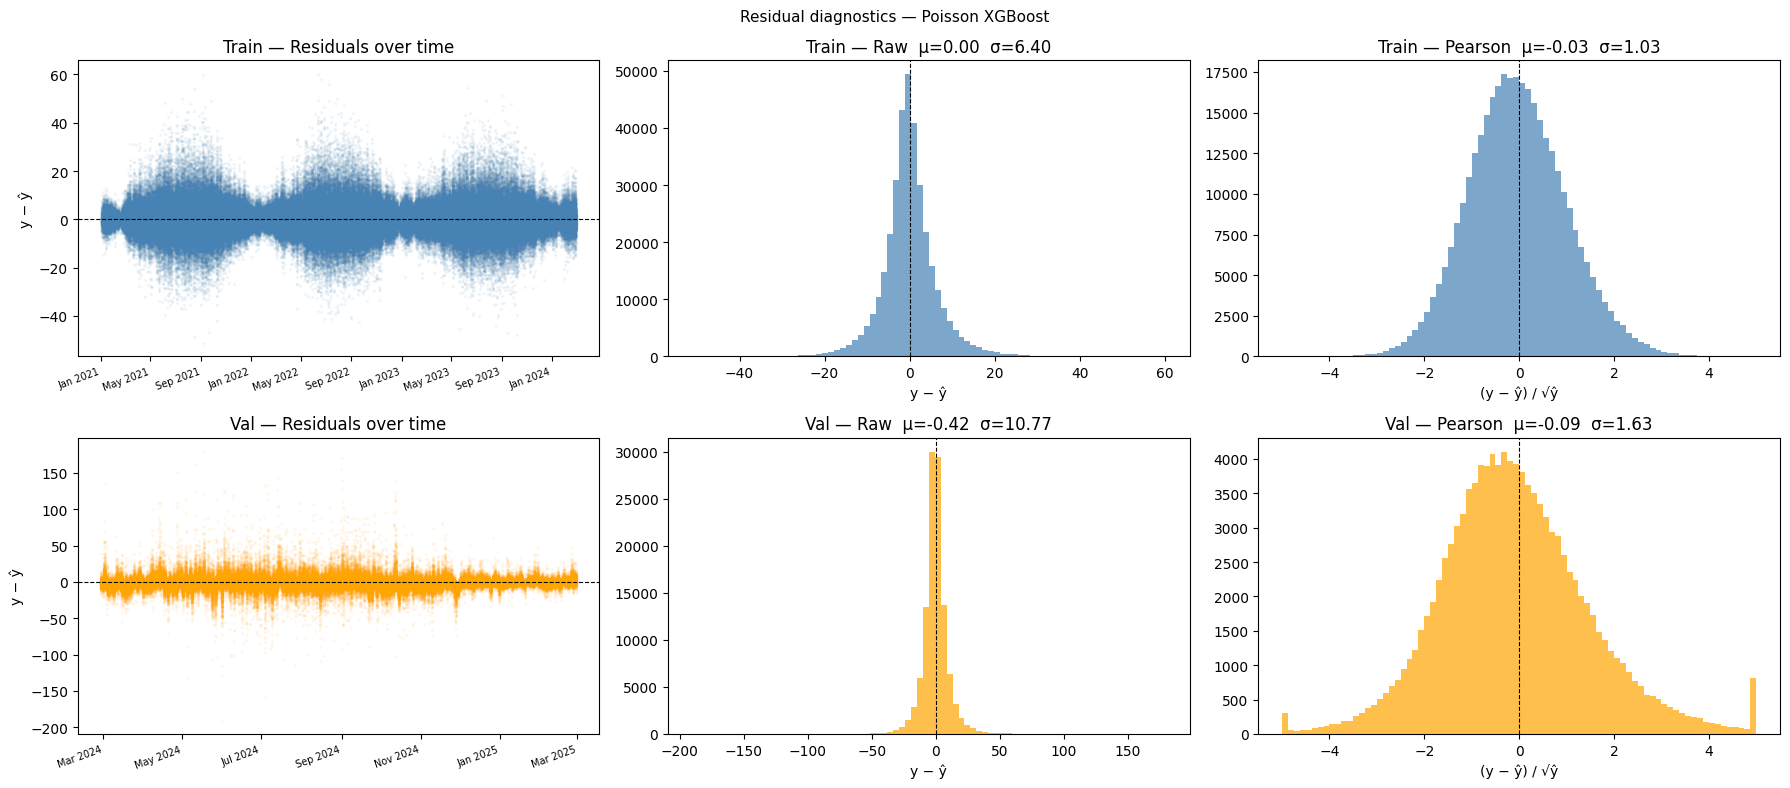

Val Pearson residual std = 1.628  (expected ~1.0 if Poisson holds)
  → overdispersed: negative binomial may fit better


In [40]:
## 10. Residual distribution — raw & Pearson
fig, axes = plt.subplots(2, 3, figsize=(18, 8))

for row, (data, color, label) in enumerate([
    (train_eval, 'steelblue', 'Train'),
    (val_eval,   'orange',    'Val'),
]):
    # raw residuals over time
    axes[row,0].scatter(data['date'], data['resid'], alpha=0.05, s=2, color=color)
    axes[row,0].axhline(0, color='black', linewidth=0.8, linestyle='--')
    axes[row,0].set_title(f'{label} — Residuals over time')
    axes[row,0].set_ylabel('y − ŷ')
    axes[row,0].xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
    plt.setp(axes[row,0].xaxis.get_majorticklabels(), rotation=20, ha='right', fontsize=7)

    # raw residual histogram
    r = data['resid']
    axes[row,1].hist(r, bins=80, color=color, alpha=0.7, edgecolor='none')
    axes[row,1].axvline(0, color='black', linewidth=0.8, linestyle='--')
    axes[row,1].set_title(f'{label} — Raw  μ={r.mean():.2f}  σ={r.std():.2f}')
    axes[row,1].set_xlabel('y − ŷ')

    # Pearson residual histogram — should be ~N(0,1) if Poisson holds
    pr = data['pearson_resid']
    axes[row,2].hist(pr.clip(-5,5), bins=80, color=color, alpha=0.7, edgecolor='none')
    axes[row,2].axvline(0, color='black', linewidth=0.8, linestyle='--')
    axes[row,2].set_title(f'{label} — Pearson  μ={pr.mean():.2f}  σ={pr.std():.2f}')
    axes[row,2].set_xlabel('(y − ŷ) / √ŷ')

fig.suptitle('Residual diagnostics — Poisson XGBoost', fontsize=11)
plt.tight_layout(); plt.show()

# Overdispersion check: if Pearson σ >> 1 → data is overdispersed for Poisson
val_pr_std = val_eval['pearson_resid'].std()
print(f'Val Pearson residual std = {val_pr_std:.3f}  (expected ~1.0 if Poisson holds)')
if val_pr_std > 1.5:
    print('  → overdispersed: negative binomial may fit better')
elif val_pr_std < 0.7:
    print('  → underdispersed')
else:
    print('  → roughly Poisson')


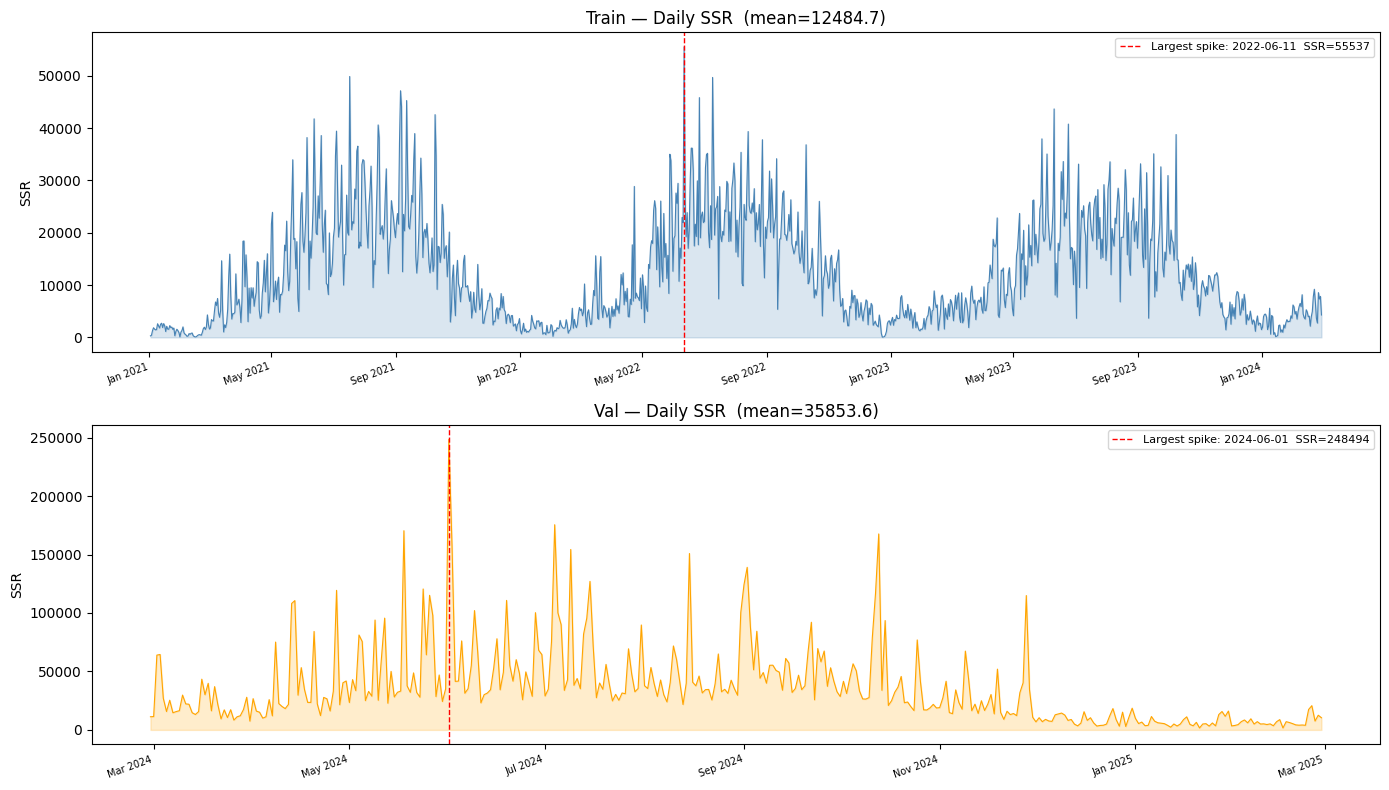

In [41]:
## 11. Daily SSR
train_eval['resid2'] = train_eval['resid'] ** 2
val_eval['resid2']   = val_eval['resid'] ** 2

ssr_train = train_eval.groupby('date')['resid2'].sum()
ssr_val   = val_eval.groupby('date')['resid2'].sum()

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=False)
for ax, ssr, color, label in [
    (axes[0], ssr_train, 'steelblue', 'Train'),
    (axes[1], ssr_val,   'orange',    'Val'),
]:
    worst = ssr.idxmax()
    ax.plot(ssr.index, ssr.values, linewidth=0.8, color=color)
    ax.fill_between(ssr.index, ssr.values, alpha=0.2, color=color)
    ax.axvline(worst, color='red', linewidth=1, linestyle='--',
               label=f'Largest spike: {worst.date()}  SSR={ssr[worst]:.0f}')
    ax.set_title(f'{label} — Daily SSR  (mean={ssr.mean():.1f})')
    ax.set_ylabel('SSR'); ax.legend(fontsize=8)
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
    plt.setp(ax.xaxis.get_majorticklabels(), rotation=20, ha='right', fontsize=7)
plt.tight_layout(); plt.show()


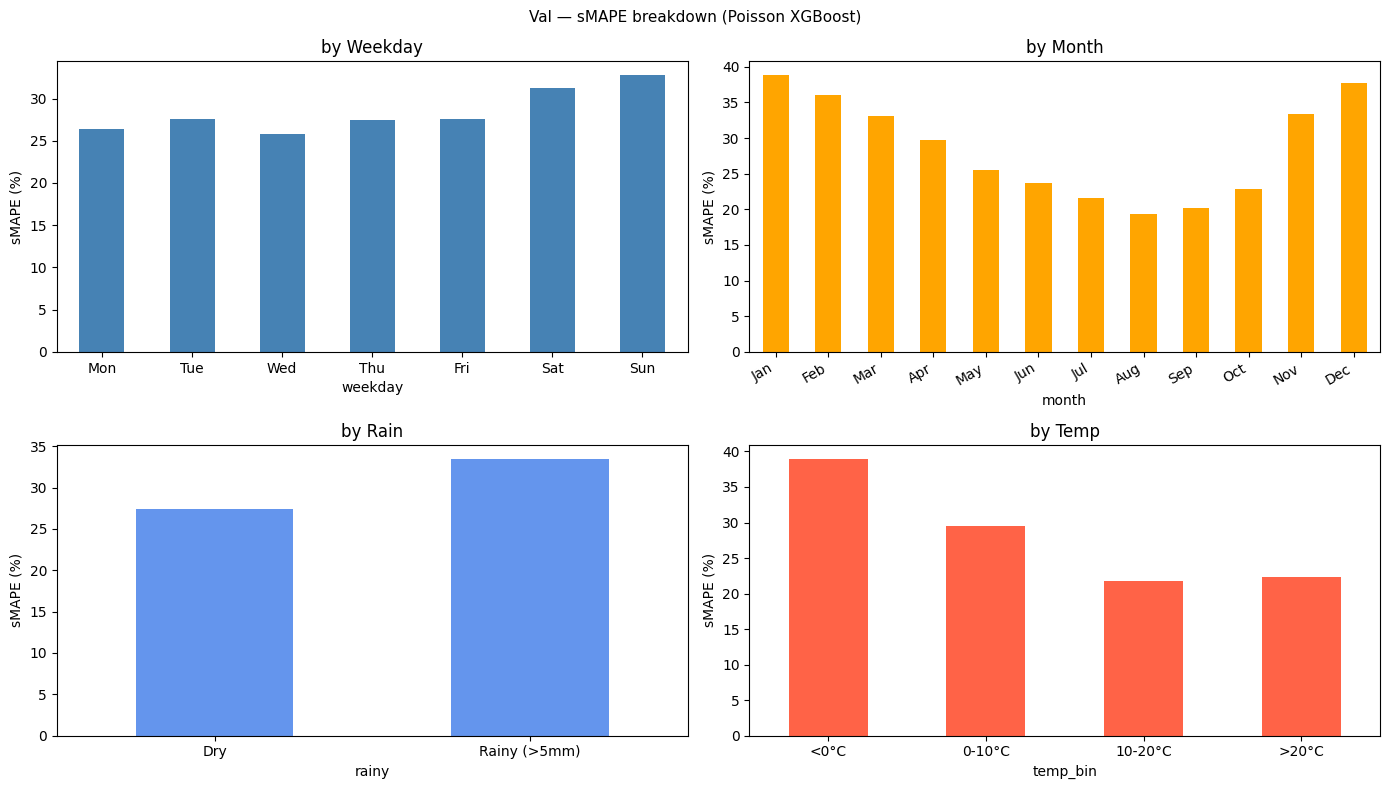

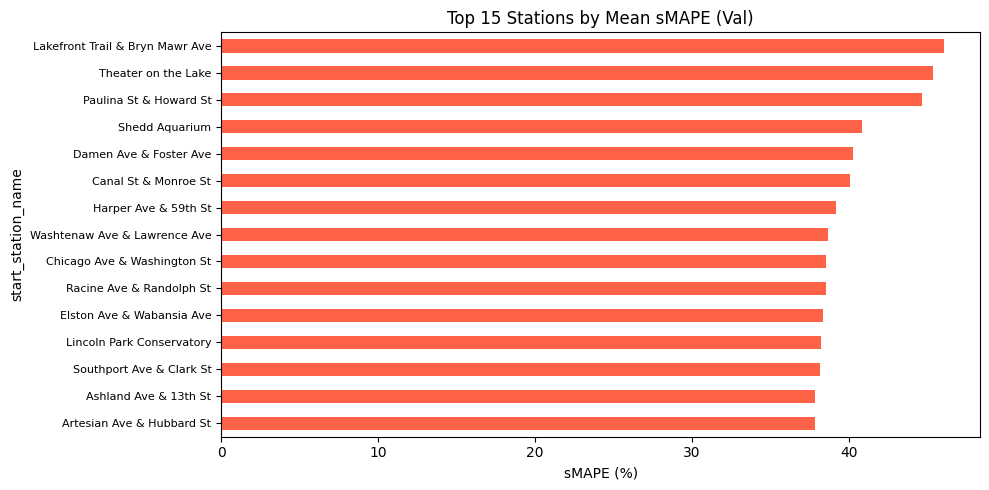

In [42]:
## 12. sMAPE breakdown by weekday / month / rain / temp
def _smape_series(true, pred):
    return 2 * np.abs(pred - true) / (np.abs(true) + np.abs(pred))

val_eval['smape']   = _smape_series(val_eval['total_rides'], val_eval['pred']) * 100
val_eval['weekday'] = val_eval['date'].dt.weekday
val_eval['month']   = val_eval['date'].dt.month

weather_day = df[['date','rain_sum_mm','temp_min_c']].drop_duplicates('date')
val_w = val_eval.merge(weather_day, on='date', how='left')
val_w['rainy']    = (val_w['rain_sum_mm'] > 5).map({True: 'Rainy (>5mm)', False: 'Dry'})
val_w['temp_bin'] = pd.cut(val_w['temp_min_c'], bins=[-30,0,10,20,40],
                            labels=['<0°C','0-10°C','10-20°C','>20°C'])

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
fig.suptitle('Val — sMAPE breakdown (Poisson XGBoost)', fontsize=11)

val_eval.groupby('weekday')['smape'].mean().plot.bar(ax=axes[0,0], color='steelblue', edgecolor='none')
axes[0,0].set_title('by Weekday'); axes[0,0].set_ylabel('sMAPE (%)')
axes[0,0].set_xticklabels(['Mon','Tue','Wed','Thu','Fri','Sat','Sun'], rotation=0)

val_eval.groupby('month')['smape'].mean().plot.bar(ax=axes[0,1], color='orange', edgecolor='none')
axes[0,1].set_title('by Month'); axes[0,1].set_ylabel('sMAPE (%)')
axes[0,1].set_xticklabels(['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec'], rotation=30, ha='right')

val_w.groupby('rainy')['smape'].mean().plot.bar(ax=axes[1,0], color='cornflowerblue', edgecolor='none')
axes[1,0].set_title('by Rain'); axes[1,0].set_ylabel('sMAPE (%)')
axes[1,0].tick_params(axis='x', rotation=0)

val_w.groupby('temp_bin', observed=True)['smape'].mean().plot.bar(ax=axes[1,1], color='tomato', edgecolor='none')
axes[1,1].set_title('by Temp'); axes[1,1].set_ylabel('sMAPE (%)')
axes[1,1].tick_params(axis='x', rotation=0)

plt.tight_layout(); plt.show()

stn_smape = val_eval.groupby('start_station_name')['smape'].mean().sort_values(ascending=False).head(15)
fig, ax = plt.subplots(figsize=(10, 5))
stn_smape.sort_values().plot.barh(ax=ax, color='tomato', edgecolor='none')
ax.set_title('Top 15 Stations by Mean sMAPE (Val)')
ax.set_xlabel('sMAPE (%)'); ax.tick_params(axis='y', labelsize=8)
plt.tight_layout(); plt.show()


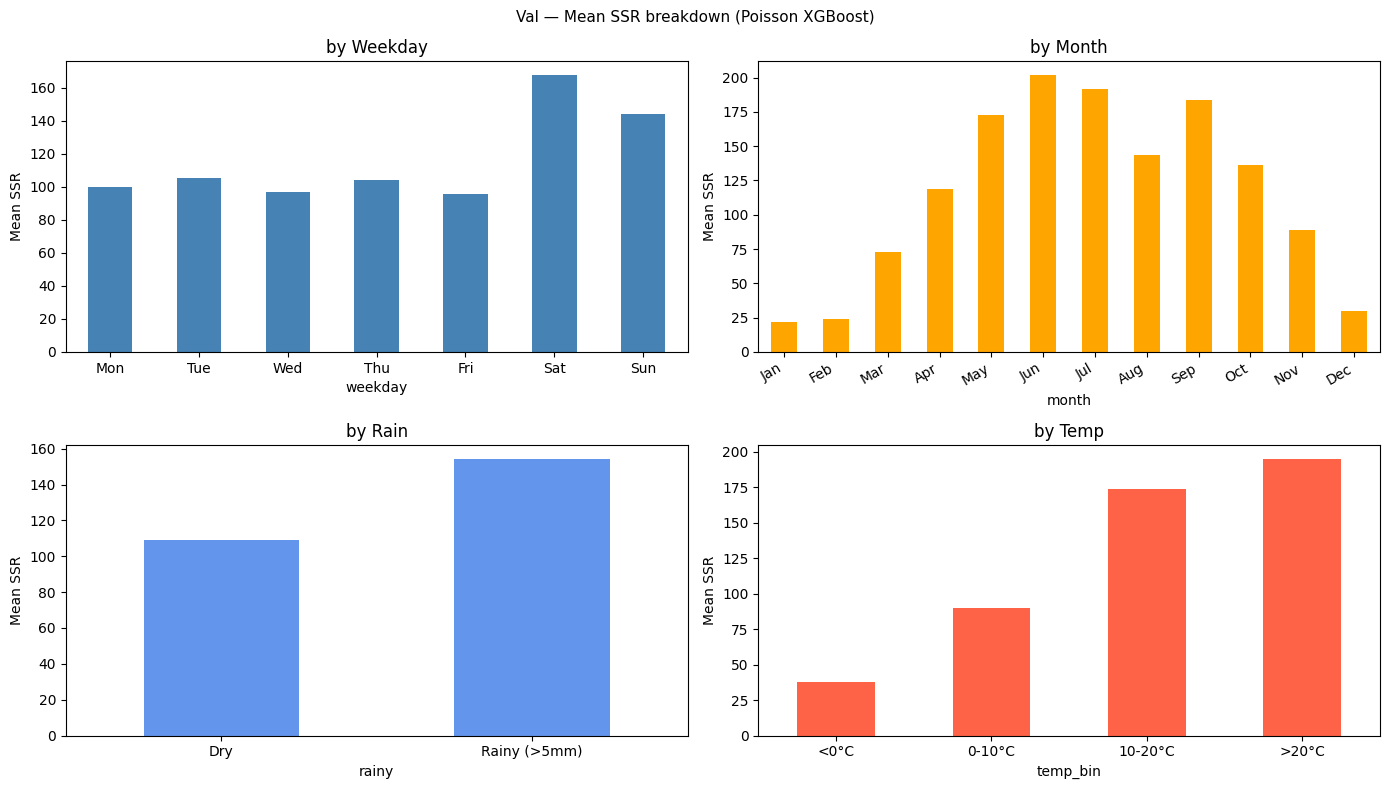

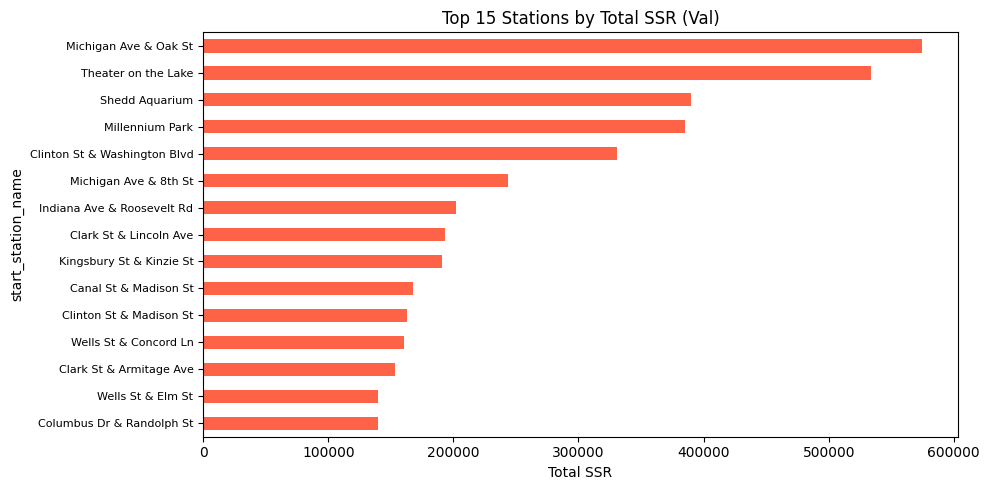

In [43]:
## 13. SSR breakdown by weekday / month / rain / temp
val_eval['resid2']  = val_eval['resid'] ** 2
val_eval['weekday'] = val_eval['date'].dt.weekday
val_eval['month']   = val_eval['date'].dt.month

val_w2 = val_eval.merge(weather_day, on='date', how='left')
val_w2['rainy']    = (val_w2['rain_sum_mm'] > 5).map({True: 'Rainy (>5mm)', False: 'Dry'})
val_w2['temp_bin'] = pd.cut(val_w2['temp_min_c'], bins=[-30,0,10,20,40],
                             labels=['<0°C','0-10°C','10-20°C','>20°C'])

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
fig.suptitle('Val — Mean SSR breakdown (Poisson XGBoost)', fontsize=11)

val_eval.groupby('weekday')['resid2'].mean().plot.bar(ax=axes[0,0], color='steelblue', edgecolor='none')
axes[0,0].set_title('by Weekday'); axes[0,0].set_ylabel('Mean SSR')
axes[0,0].set_xticklabels(['Mon','Tue','Wed','Thu','Fri','Sat','Sun'], rotation=0)

val_eval.groupby('month')['resid2'].mean().plot.bar(ax=axes[0,1], color='orange', edgecolor='none')
axes[0,1].set_title('by Month'); axes[0,1].set_ylabel('Mean SSR')
axes[0,1].set_xticklabels(['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec'], rotation=30, ha='right')

val_w2.groupby('rainy')['resid2'].mean().plot.bar(ax=axes[1,0], color='cornflowerblue', edgecolor='none')
axes[1,0].set_title('by Rain'); axes[1,0].set_ylabel('Mean SSR')
axes[1,0].tick_params(axis='x', rotation=0)

val_w2.groupby('temp_bin', observed=True)['resid2'].mean().plot.bar(ax=axes[1,1], color='tomato', edgecolor='none')
axes[1,1].set_title('by Temp'); axes[1,1].set_ylabel('Mean SSR')
axes[1,1].tick_params(axis='x', rotation=0)

plt.tight_layout(); plt.show()

stn_ssr = val_eval.groupby('start_station_name')['resid2'].sum().sort_values(ascending=False).head(15)
fig, ax = plt.subplots(figsize=(10, 5))
stn_ssr.sort_values().plot.barh(ax=ax, color='tomato', edgecolor='none')
ax.set_title('Top 15 Stations by Total SSR (Val)')
ax.set_xlabel('Total SSR'); ax.tick_params(axis='y', labelsize=8)
plt.tight_layout(); plt.show()


In [44]:
## 7. Side-by-side comparison with MSE model (notebook 06)
import os

MSE_MODEL_PATH = '../models/xgb_station_1day.json'
if os.path.exists(MSE_MODEL_PATH):
    mse_model = XGBRegressor()
    mse_model.load_model(MSE_MODEL_PATH)
    y_pred_val_mse  = np.maximum(mse_model.predict(X_val),  0)
    y_pred_test_mse = np.maximum(mse_model.predict(X_test), 0)

    compare = pd.DataFrame({
        'MSE — Val':     metrics_dict(y_val,  y_pred_val_mse,  y_train),
        'MSE — Test':    metrics_dict(y_test, y_pred_test_mse, y_train),
        'Poisson — Val': metrics_dict(y_val,  y_pred_val,      y_train),
        'Poisson — Test':metrics_dict(y_test, y_pred_test,     y_train),
    }).T.round(4)
    display(compare)
else:
    print(f'MSE model not found at {MSE_MODEL_PATH} — run notebook 06 first to save it.')


MSE model not found at ../models/xgb_station_1day.json — run notebook 06 first to save it.


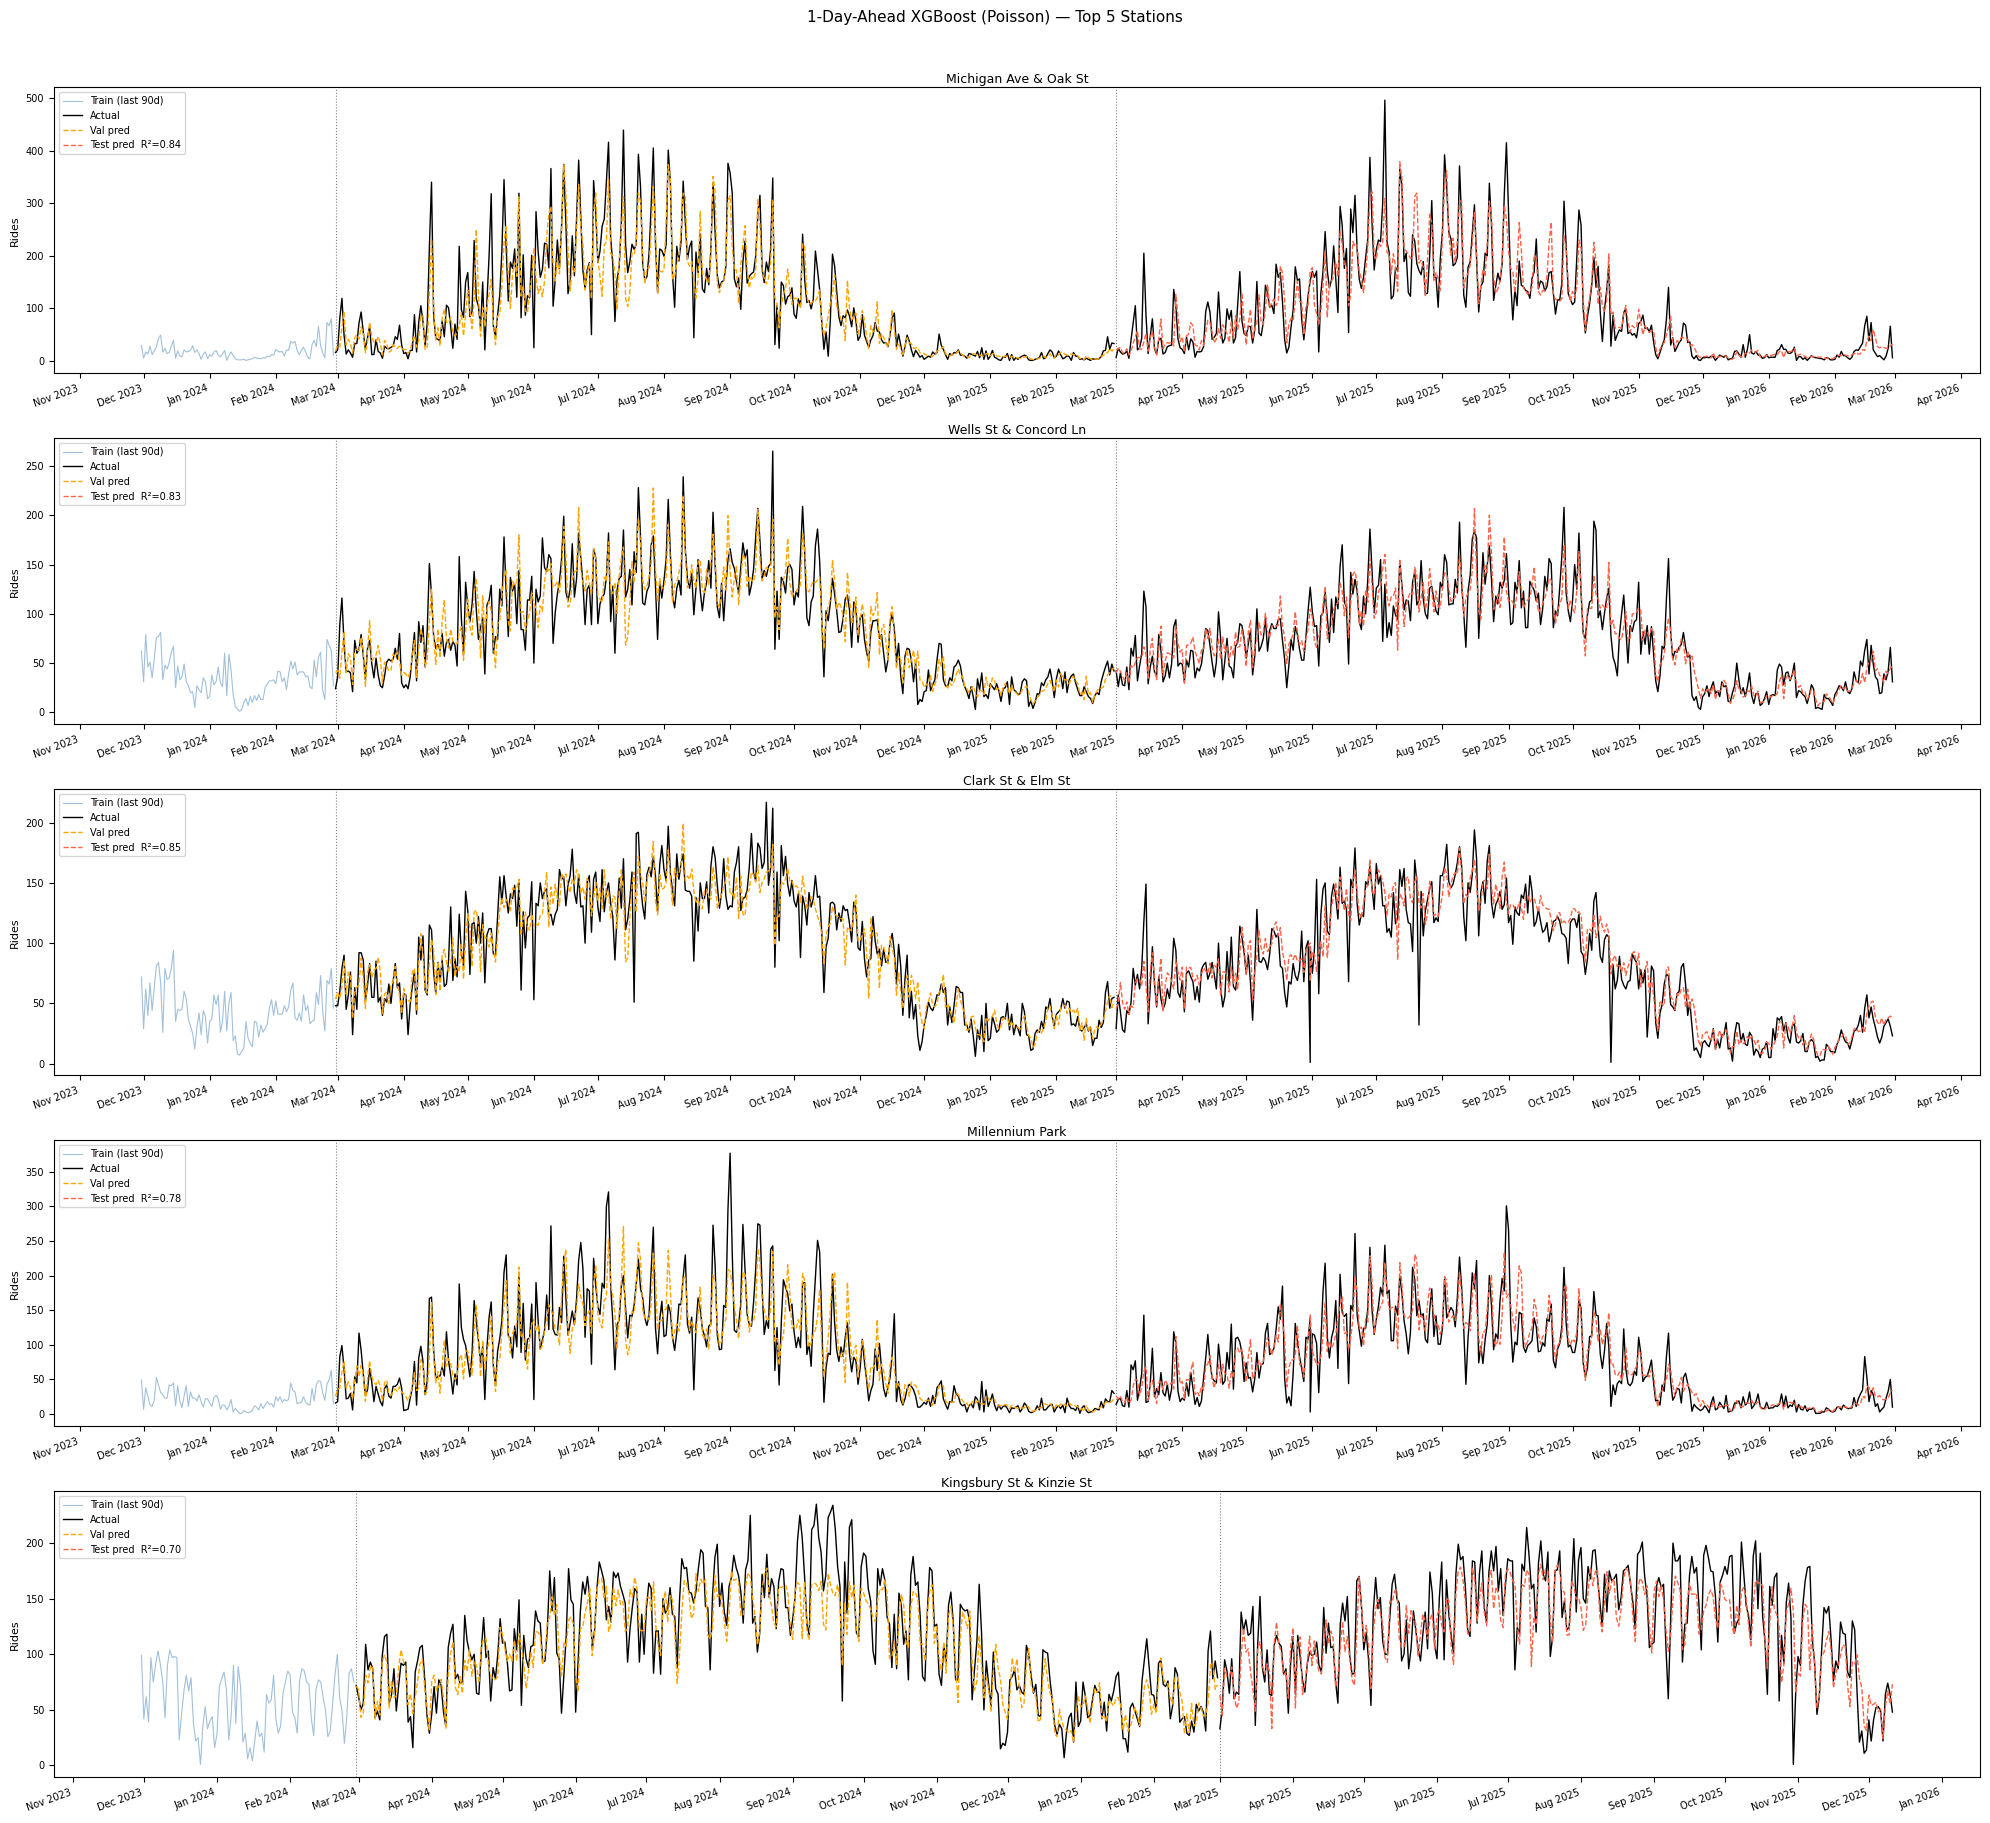

In [45]:
## 8. Visualise — top 5 stations
top5 = (
    train.groupby('start_station_name')['total_rides']
    .sum().sort_values(ascending=False).head(5).index.tolist()
)

CONTEXT_DAYS = 90
fig, axes = plt.subplots(5, 1, figsize=(20, 18), sharex=False)
for ax, name in zip(axes, top5):
    tr   = train[train['start_station_name'] == name]
    tr_ctx = tr[tr['date'] >= tr['date'].max() - pd.Timedelta(days=CONTEXT_DAYS)]
    vl   = val_eval[val_eval['start_station_name']  == name].sort_values('date')
    te   = test_eval[test_eval['start_station_name'] == name].sort_values('date')
    r2_s = per_station.loc[name, 'r2']

    ax.plot(tr_ctx['date'], tr_ctx['total_rides'], color='steelblue', alpha=0.5, linewidth=0.8, label='Train (last 90d)')
    ax.axvline(vl['date'].min(), color='grey', linestyle=':', linewidth=0.8)
    ax.axvline(te['date'].min(), color='grey', linestyle=':', linewidth=0.8)
    ax.plot(vl['date'], vl['total_rides'], color='black',  linewidth=1, label='Actual')
    ax.plot(vl['date'], vl['pred'],        color='orange', linestyle='--', linewidth=1, label='Val pred')
    ax.plot(te['date'], te['total_rides'], color='black',  linewidth=1)
    ax.plot(te['date'], te['pred'],        color='tomato', linestyle='--', linewidth=1, label=f'Test pred  R²={r2_s:.2f}')
    ax.set_title(name, fontsize=9, pad=3)
    ax.set_ylabel('Rides', fontsize=8)
    ax.legend(fontsize=7, loc='upper left')
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
    ax.xaxis.set_major_locator(mdates.MonthLocator())
    plt.setp(ax.xaxis.get_majorticklabels(), rotation=20, ha='right', fontsize=7)
    ax.tick_params(axis='y', labelsize=7)

fig.suptitle('1-Day-Ahead XGBoost (Poisson) — Top 5 Stations', fontsize=11, y=1.01)
plt.tight_layout(); plt.show()
